In [1]:
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
import numpy as np
import seaborn as sns
import pandas as pd
from sklearn.metrics import confusion_matrix
from tensorflow.keras import layers
import matplotlib.pyplot as plt

In [3]:
data = pd.read_csv('cifar-10.csv')

In [4]:
data.head()

,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_3063,pixel_3064,pixel_3065,pixel_3066,pixel_3067,pixel_3068,pixel_3069,pixel_3070,pixel_3071,label
0,59,43,50,68,98,119,139,145,149,149,...,58,65,59,46,57,104,140,84,72,6
1,154,126,105,102,125,155,172,180,142,111,...,42,67,101,122,133,136,139,142,144,9
2,255,253,253,253,253,253,253,253,253,253,...,83,80,69,66,72,79,83,83,84,9
3,28,37,38,42,44,40,40,24,32,43,...,39,59,42,44,48,38,28,37,46,4
4,170,168,177,183,181,177,181,184,189,189,...,88,85,82,83,79,78,82,78,80,1


In [5]:
x = data.drop('label',axis=1).values
y = data['label'].values

In [6]:
x = x / 255.0
x = x.reshape(-1,32,32,3)

In [7]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [8]:
model = keras.Sequential([
    layers.Input(shape=(32,32,3)),
    layers.Conv2D(32,(3,3), activation = 'relu'),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64,(3,3), activation = 'relu'),
    layers.MaxPooling2D((2,2)),

    layers.Flatten(),

    layers.Dense(128,activation = 'relu'),
    layers.Dense(10,activation = 'softmax')
])

In [9]:
model.compile(
    optimizer = 'adam',
    loss = 'sparse_categorical_crossentropy',
    metrics = ['accuracy']
)

In [10]:
history = model.fit(
    x_train,y_train,
    epochs = 10,
    batch_size = 32,
    validation_data = (x_test,y_test)
)

Epoch 1/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.4290 - loss: 1.5979 - val_accuracy: 0.4899 - val_loss: 1.4486
Epoch 2/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.5446 - loss: 1.2915 - val_accuracy: 0.5524 - val_loss: 1.2598
Epoch 3/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.5947 - loss: 1.1528 - val_accuracy: 0.5976 - val_loss: 1.1546
Epoch 4/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.6238 - loss: 1.0641 - val_accuracy: 0.6173 - val_loss: 1.1032
Epoch 5/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.6563 - loss: 0.9818 - val_accuracy: 0.6184 - val_loss: 1.0984
Epoch 6/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.6798 - loss: 0.9173 - val_accuracy: 0.6178 - val_loss: 1.1090
Epoch 7/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.6994 - loss: 0.8583 - val_accuracy: 0.6370 - val_loss: 1.0782
Epoch 8/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.7209 - loss: 0.7943 - 

In [11]:
loss, accuracy = model.evaluate(x_test,y_test)
print("Training accuracry = ", history.history['accuracy'][-1] * 100)
print("Testing accuracy =" , accuracy *100)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6365 - loss: 1.1361 
Training accuracry =  75.96250176429749
Testing accuracy = 63.65000009536743


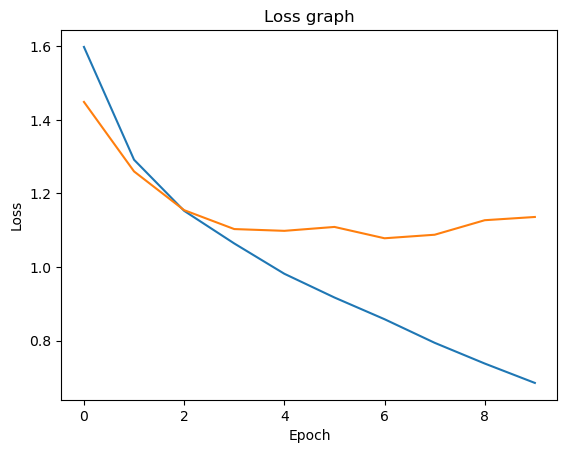

In [12]:
plt.plot(history.history['loss'],label='training loss')
plt.plot(history.history['val_loss'],label="testing loss")

plt.title('Loss graph')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.show()

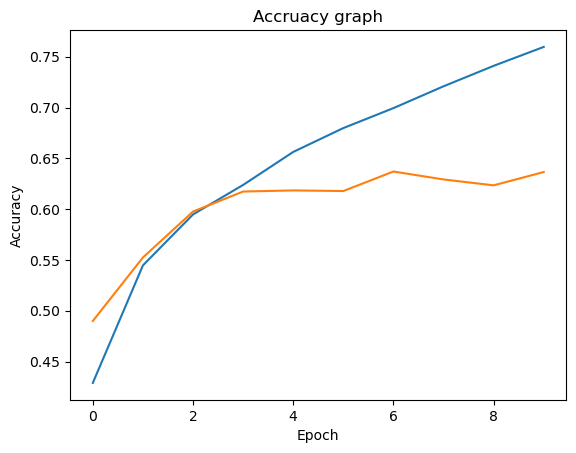

In [13]:
plt.plot(history.history['accuracy'],label = "training accuracy")
plt.plot(history.history['val_accuracy'],label = "testing accuracy")

plt.title("Accruacy graph")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.show()

In [14]:
predictions = model.predict(x_test)
prediction_labels = np.argmax(predictions,axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step  


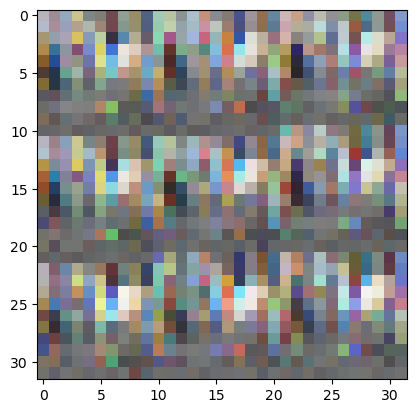

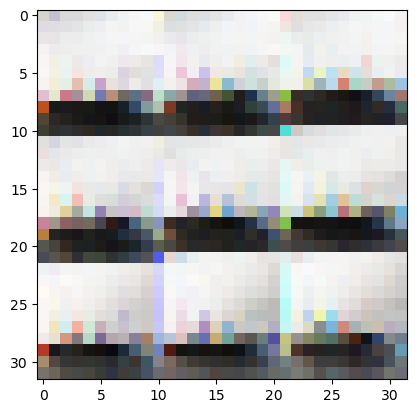

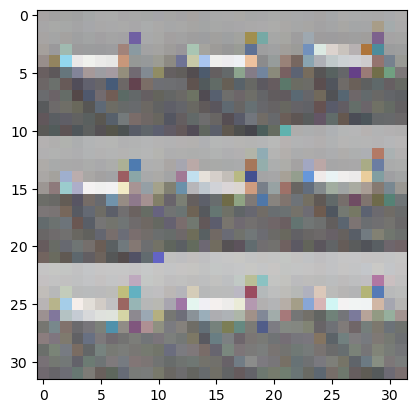

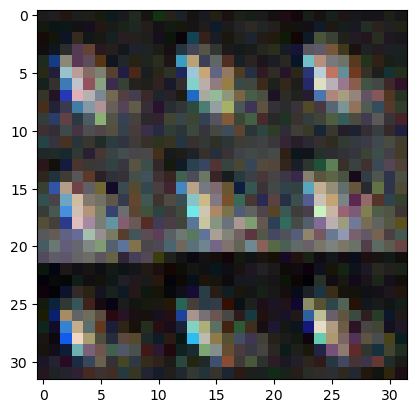

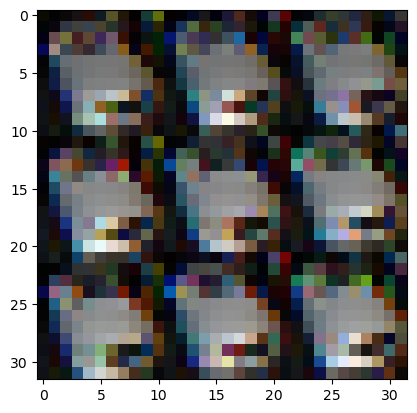

In [16]:
for i in range(5):
    plt.imshow(x_test[i].reshape(32,32,3))
    plt.show()


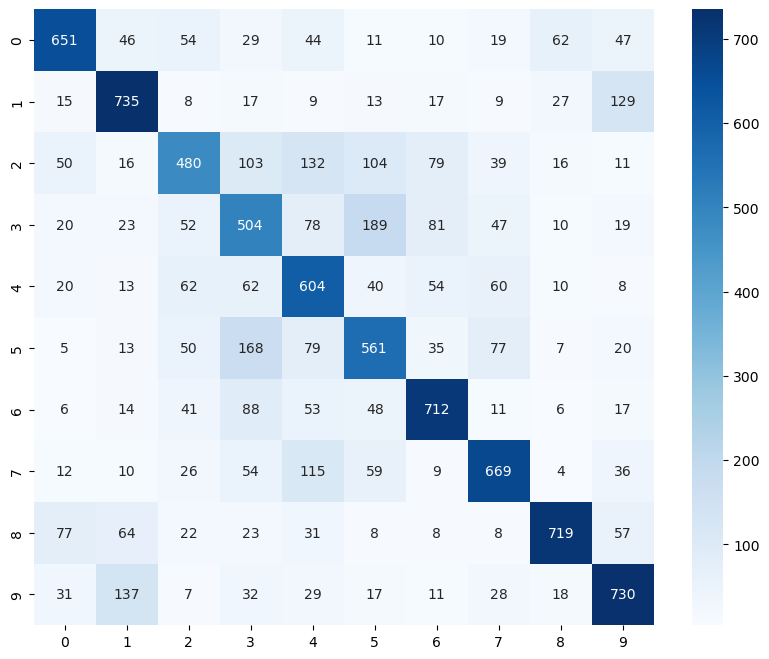

In [20]:
cm = confusion_matrix(y_test,prediction_labels)
plt.figure(figsize=(10,8))
sns.heatmap(cm,annot=True,fmt = 'd',cmap='Blues')
plt.show()